# B13 — Ridge en forme fermée et validation croisée 5-fold à la main

**Objectif.** Coder Ridge depuis la formule fermée, puis choisir $\rho$ par une validation croisée 5-fold écrite à la main. Ensuite, comparer avec scikit-learn (`GridSearchCV`, `RidgeCV`) et évaluer une seule fois sur le jeu de test.

**Durée visée :** 1 h 30.

**Règles du jeu**

- Complète les cellules marquées `# TODO`. Les fonctions lèvent `NotImplementedError` tant qu'elles ne sont pas écrites.
- Après chaque partie, une cellule **Checkpoint** vérifie ton code et affiche ✅ ou ❌.
- Avant la partie 5, utilise uniquement NumPy (les checkpoints, eux, ont le droit d'utiliser scikit-learn).
- Le jeu de **test** reste fermé jusqu'à la partie 6.

**Notations**

- On suit CS229 : $n$ exemples, $d$ features. HOML note $m$ exemples et $n$ features.
- $\rho$ est le coefficient de régularisation (le $\lambda$ des notes, le $\alpha$ de HOML et de scikit-learn).
- Le coût minimisé est

$$J(\theta) = \sum_{i=1}^{n}\left(y^{(i)} - \theta_{0} - \sum_{j=1}^{d}\theta_{j}\,x_{j}^{(i)}\right)^{2} + \rho\sum_{j=1}^{d}\theta_{j}^{2}$$

Ce coût est **exactement** celui de `sklearn.linear_model.Ridge(alpha=rho)` : somme des carrés sans facteur $1/n$, et intercept $\theta_{0}$ non pénalisé.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=False)
plt.rcParams["figure.figsize"] = (8, 4.5)

def ok(condition, message):
    print(("✅ " if condition else "❌ ") + message)
    return bool(condition)

## Partie 1 — Les données (fournies)

On veut modéliser le coefficient de portance $C_{z}$ d'un profil en fonction de l'incidence. On note $x = \alpha_{\text{incidence}} / 20°$ l'incidence normalisée, donc $x \in [0, 1]$.

La « vraie » loi, inconnue en pratique, est linéaire jusqu'à 12°, puis s'infléchit avant le décrochage. On dispose de :

- **20 essais en soufflerie** (`x_tr`, `y_tr`), entachés d'un bruit de mesure gaussien d'écart-type $\sigma = 0{,}1$. C'est le jeu d'entraînement.
- **2 000 points de test** (`x_te`, `y_te`), à ne pas toucher avant la partie 6.

Le meilleur modèle possible a donc une MSE de test d'environ $\sigma^{2} = 0{,}01$ : c'est le plancher du bruit.

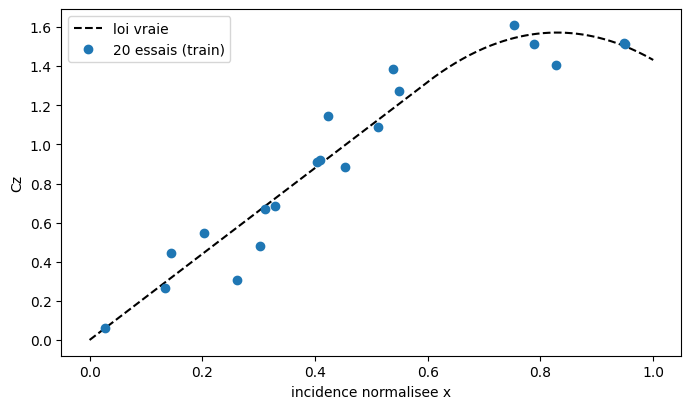

In [2]:
SIGMA = 0.1
DEG = 15          # degre du polynome : volontairement beaucoup trop grand pour 20 points

def cz_vrai(x):
    a = 20 * x                                   # incidence en degres
    return 0.11 * a - 0.012 * np.maximum(a - 12, 0) ** 2

def generer(n, seed, sigma=SIGMA):
    rng = np.random.default_rng(seed)
    x = np.sort(rng.uniform(0, 1, n))
    return x, cz_vrai(x) + rng.normal(0, sigma, n)

x_tr, y_tr = generer(20, seed=1)
x_te, y_te = generer(2000, seed=99)

x_grille = np.linspace(0, 1, 400)
plt.plot(x_grille, cz_vrai(x_grille), "k--", label="loi vraie")
plt.plot(x_tr, y_tr, "o", label="20 essais (train)")
plt.xlabel("incidence normalisee x"); plt.ylabel("Cz"); plt.legend(); plt.show()

## Partie 2 — Features polynomiales et standardisation

Chaque scalaire $x^{(i)}$ devient un vecteur de $d = 15$ features :

$$\phi\big(x^{(i)}\big) = \begin{pmatrix} x^{(i)} & \big(x^{(i)}\big)^{2} & \cdots & \big(x^{(i)}\big)^{15} \end{pmatrix} \in \mathbb{R}^{1 \times 15}, \qquad P = \begin{pmatrix} \phi\big(x^{(1)}\big) \\ \vdots \\ \phi\big(x^{(n)}\big) \end{pmatrix} \in \mathbb{R}^{n \times 15}$$

Pas de colonne de 1 ici : l'intercept sera ajouté dans `ridge_ferme`.

On standardise ensuite chaque colonne $j$ avec la moyenne $\mu_{j}$ et l'écart-type $s_{j}$ **calculés sur les données d'entraînement seulement** :

$$X_{ij} = \frac{P_{ij} - \mu_{j}}{s_{j}}$$

Utilise `np.std` avec son option par défaut (`ddof=0`), comme `StandardScaler`.

In [3]:
def poly(x, deg=DEG):
    P=np.vander(x, deg+1, increasing=True)[:, 1:]
    return P

test=poly([1])
print(test.shape)
print(test)

def standardiser_fit(P):
    mu=np.mean(P,axis=0)
    s=np.std(P,axis=0)
    return mu, s

test=standardiser_fit(poly([1]))
print(len(test[1]))
print(test)

def standardiser(P, mu, s):
    X = (P-mu)/s
    return(X)

super_test=standardiser([1], standardiser_fit(poly([1]))[0], standardiser_fit(poly([1]))[1])

(1, 15)
[[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]]
15
(array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]), array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]))


C:\Users\Utilisateur\AppData\Local\Temp\ipykernel_30064\3828367493.py:19: RuntimeWarning: invalid value encountered in divide
  X = (P-mu)/s


In [4]:
# Checkpoint 2
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

P_tr = poly(x_tr)
mu_tr, s_tr = standardiser_fit(P_tr)
X_tr = standardiser(P_tr, mu_tr, s_tr)

ok(P_tr.shape == (20, DEG), f"forme de P : {P_tr.shape}")
ok(np.allclose(P_tr, PolynomialFeatures(DEG, include_bias=False).fit_transform(x_tr[:, None])), "poly identique a PolynomialFeatures")
ok(np.allclose(X_tr, StandardScaler().fit_transform(P_tr)), "standardisation identique a StandardScaler")
ok(np.allclose(X_tr.mean(axis=0), 0) and np.allclose(X_tr.std(axis=0), 1), "colonnes de moyenne 0 et d'ecart-type 1")

✅ forme de P : (20, 15)
✅ poly identique a PolynomialFeatures
✅ standardisation identique a StandardScaler
✅ colonnes de moyenne 0 et d'ecart-type 1


True

## Partie 3 — Ridge en forme fermée

On ajoute une colonne de 1 à $X$ pour l'intercept, et on ne pénalise pas $\theta_{0}$ :

$$X_{b} = \begin{pmatrix} 1 & X_{11} & \cdots & X_{1d} \\ \vdots & \vdots & \ddots & \vdots \\ 1 & X_{n1} & \cdots & X_{nd} \end{pmatrix} \in \mathbb{R}^{n \times (d+1)}, \qquad A = \begin{pmatrix} 0 & 0 & \cdots & 0 \\ 0 & 1 & \cdots & 0 \\ \vdots & \vdots & \ddots & \vdots \\ 0 & 0 & \cdots & 1 \end{pmatrix} \in \mathbb{R}^{(d+1) \times (d+1)}$$

$$\hat{\theta} = \left(X_{b}^{\top}X_{b} + \rho A\right)^{-1} X_{b}^{\top}y \in \mathbb{R}^{d+1}$$

Utilise `np.linalg.solve`, pas `np.linalg.inv`.

La prédiction vaut $\hat{y} = \theta_{0} + X\,\theta_{1:d}$.

In [5]:
def ridge_ferme(X, y, rho):
    # TODO : construire Xb et A, puis resoudre (Xb^T Xb + rho A) theta = Xb^T y
    n,d=X.shape
    Xb = np.hstack([np.ones((n, 1)), X])
    A = np.eye(d+1)
    A[0,0] = 0
    theta_sol=np.linalg.solve(Xb.T @ Xb + rho*A, Xb.T @ y)
    return theta_sol
    # renvoyer theta de forme (d+1,) avec theta[0] = intercept
    raise NotImplementedError

def predire(X, theta):
    # TODO : renvoyer theta[0] + X @ theta[1:]
    y = theta[0] + X @ theta[1:]
    return y

def mse(y_pred, y):
    return np.mean((y_pred - y) ** 2)

In [11]:
# Checkpoint 3
from sklearn.linear_model import Ridge

for rho in [1e-3, 1.0, 10.0]:
    theta = ridge_ferme(X_tr, y_tr, rho)
    ref = Ridge(alpha=rho).fit(X_tr, y_tr)
    ok(theta.shape == (DEG + 1,), f"rho={rho:g} : forme de theta {theta.shape}")
    ok(np.allclose(theta[1:], ref.coef_, atol=1e-6) and np.isclose(theta[0], ref.intercept_),
       f"rho={rho:g} : coefficients identiques a sklearn Ridge")
ok(np.isclose(mse(np.array([1., 2.]), np.array([0., 0.])), 2.5), "mse correcte")
print("intercept :", ridge_ferme(X_tr, y_tr, 1.0)[0], "| moyenne de y_tr :", y_tr.mean())

✅ rho=0.001 : forme de theta (16,)
✅ rho=0.001 : coefficients identiques a sklearn Ridge
✅ rho=1 : forme de theta (16,)
✅ rho=1 : coefficients identiques a sklearn Ridge
✅ rho=10 : forme de theta (16,)
✅ rho=10 : coefficients identiques a sklearn Ridge
✅ mse correcte
intercept : 0.9316505452460404 | moyenne de y_tr : 0.9316505452460404


### Partie 3b — Effet de $\rho$

Pour $\rho \in \{10^{-8},\ 10^{-3},\ 10^{-1},\ 10,\ 10^{3}\}$, ajuste Ridge sur les 20 points et :

1. trace la courbe prédite sur `x_grille`, avec les points d'entraînement et la loi vraie ;
2. affiche la norme $\|\theta_{1:d}\|$ et le conditionnement de $X_{b}^{\top}X_{b} + \rho A$ (`np.linalg.cond`).

$\rho = 10^{-8}$ joue le rôle de l'OLS.

Attention : la grille doit être transformée avec `mu_tr` et `s_tr`, pas restandardisée.

rho=   1e-08   ||theta||= 3.269e+02   cond= 2.81e+10
rho=   1e-03   ||theta||= 1.701e+00   cond= 2.81e+05
rho=   1e-01   ||theta||= 6.883e-01   cond= 2.81e+03
rho=   1e+01   ||theta||= 2.403e-01   cond= 2.91e+01
rho=   1e+03   ||theta||= 1.808e-02   cond= 6.41e+01


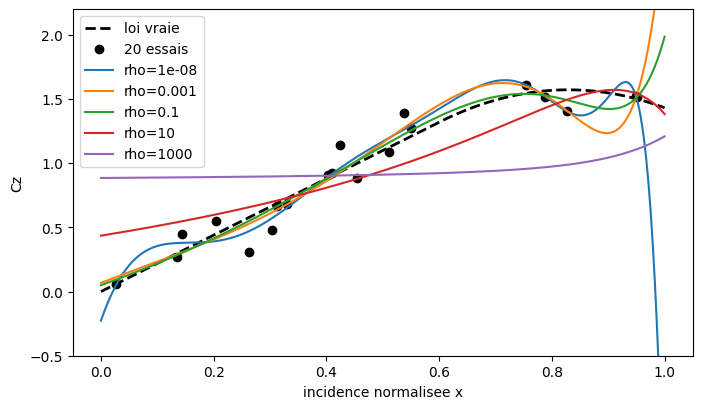

In [12]:
X_grille = standardiser(poly(x_grille), mu_tr, s_tr)
Xb_tr = np.hstack([np.ones((len(x_tr),1)), X_tr])
A=np.eye(DEG+1)
A[0,0]=0

plt.plot(x_grille, cz_vrai(x_grille), "k--", lw=2, label="loi vraie")
plt.plot(x_tr, y_tr, "ko", label="20 essais")

for rho in [1e-8, 1e-3, 1e-1, 1e1, 1e3]:
    theta = ridge_ferme(X_tr, y_tr, rho)
    cond = np.linalg.cond(Xb_tr.T @ Xb_tr + rho * A)
    print(f"rho={rho:8.0e}   ||theta||={np.linalg.norm(theta[1:]):10.3e}   cond={cond:9.2e}")
    plt.plot(x_grille, predire(X_grille, theta), label=f"rho={rho:g}")

plt.ylim(-0.5, 2.2)
plt.xlabel("incidence normalisee x"); plt.ylabel("Cz")
plt.legend(); plt.show()
# TODO : boucle sur les rho, trace des courbes, affichage de ||theta|| et du conditionnement

## Partie 4 — Validation croisée 5-fold, à la main

**Découpage.** On mélange les indices $0, \ldots, n-1$ avec `np.random.default_rng(seed).permutation(n)`. On les coupe en $k$ blocs avec `np.array_split`. Le pli $i$ utilise le bloc $i$ en validation et les $k-1$ autres en entraînement.

**Score.** Pour chaque pli $i$, on refait toute la chaîne **sur le seul sous-jeu d'entraînement du pli** : `poly`, `standardiser_fit`, `ridge_ferme`. On transforme ensuite le bloc de validation avec les $\mu$ et $s$ **de ce pli**, puis on calcule la MSE. Le score final est :

$$\text{CV}(\rho) = \frac{1}{k}\sum_{i=1}^{k} \text{MSE}_{\text{val}}^{(i)}(\rho)$$

Il faut aussi renvoyer l'écart-type des $k$ MSE, et la MSE **d'entraînement** moyenne (sur les sous-jeux d'entraînement des plis).

In [8]:
def kfold_indices(n, k=5, seed=0):
    idx = np.random.default_rng(seed).permutation(n)
    blocs = np.array_split(idx, k)                         # liste de k tableaux
    folds = []
    for i in range(k):
        idx_val = blocs[i]
        idx_train = np.concatenate(blocs[:i] + blocs[i+1:])   # tous les blocs sauf le i-eme
        folds.append((idx_train, idx_val))
    return folds

for tr, va in kfold_indices(6, k=3):
    print("train :", tr, "| val :", va)


def cv_mse(x, y, rho, folds, deg=DEG):
    err_val, err_tr = [], []
    for idx_train, idx_val in folds:
        # 1. features + standardisation apprises sur le train DU PLI uniquement
        P_f = poly(x[idx_train], deg)
        mu_f, s_f = standardiser_fit(P_f)
        X_f = standardiser(P_f, mu_f, s_f)

        # 2. ajustement Ridge sur le train du pli
        theta = ridge_ferme(X_f, y[idx_train], rho)
        err_tr.append(mse(predire(X_f, theta), y[idx_train]))

        # 3. validation : on applique les mu_f, s_f DU PLI (on ne refait pas le fit)
        X_v = standardiser(poly(x[idx_val], deg), mu_f, s_f)
        err_val.append(mse(predire(X_v, theta), y[idx_val]))

    return np.mean(err_val), np.std(err_val), np.mean(err_tr)

train : [5 4 0 1] | val : [3 2]
train : [3 2 0 1] | val : [5 4]
train : [3 2 5 4] | val : [0 1]


In [9]:
# Checkpoint 4
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score

folds = kfold_indices(len(x_tr), k=5, seed=0)
toutes_val = np.sort(np.concatenate([v for _, v in folds]))
ok(len(folds) == 5, "5 plis")
ok(np.array_equal(toutes_val, np.arange(len(x_tr))), "chaque point est en validation exactement une fois")
ok(all(len(np.intersect1d(t, v)) == 0 and len(t) + len(v) == len(x_tr) for t, v in folds), "train et val disjoints dans chaque pli")

pipe = make_pipeline(PolynomialFeatures(DEG, include_bias=False), StandardScaler(), Ridge(alpha=1.0))
ref = -cross_val_score(pipe, x_tr[:, None], y_tr, cv=folds, scoring="neg_mean_squared_error").mean()
m, s, m_tr = cv_mse(x_tr, y_tr, 1.0, folds)
ok(np.isclose(m, ref), f"CV(rho=1) = {m:.5f} (sklearn : {ref:.5f})")
ok(m_tr < m, f"MSE train moyenne {m_tr:.5f} < MSE validation {m:.5f}")

✅ 5 plis
✅ chaque point est en validation exactement une fois
✅ train et val disjoints dans chaque pli
✅ CV(rho=1) = 0.02287 (sklearn : 0.02287)
✅ MSE train moyenne 0.01686 < MSE validation 0.02287


True

### Partie 4b — Choisir $\rho$

1. Calcule $\text{CV}(\rho)$, l'écart-type et la MSE d'entraînement pour `rhos = np.logspace(-8, 3, 45)`.
2. Trace la MSE de validation moyenne avec une bande $\pm$ écart-type, ainsi que la MSE d'entraînement, en fonction de $\rho$ (axes en échelle log). Ajoute une ligne horizontale à $\sigma^{2}$.
3. Repère `rho_best`, le minimiseur de $\text{CV}(\rho)$.
4. *(Bonus)* **Règle du 1-SE** : `rho_1se` est le plus **grand** $\rho$ tel que $\text{CV}(\rho) \leq \text{CV}(\rho_{\text{best}}) + \text{écart-type}(\rho_{\text{best}}) / \sqrt{k}$. C'est le modèle le plus simple qui reste statistiquement aussi bon que le meilleur.

rho_best = 3.162e-02   CV = 0.0137
rho_1se  = 3.162e-01


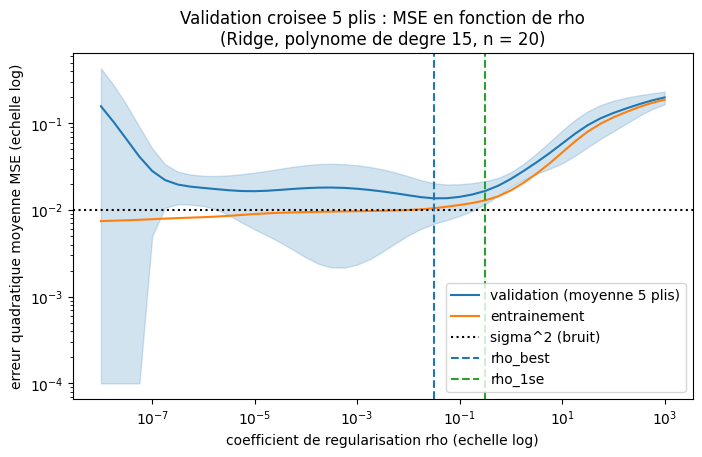

In [15]:
rhos = np.logspace(-8, 3, 45)
folds = kfold_indices(len(x_tr), k=5, seed=0)

resultats = np.array([cv_mse(x_tr, y_tr, r, folds) for r in rhos])
cv_moy, cv_std, tr_moy = resultats.T

i_best = np.argmin(cv_moy)
rho_best = rhos[i_best]
seuil = cv_moy[i_best] + cv_std[i_best] / np.sqrt(len(folds))
rho_1se = rhos[np.max(np.where(cv_moy <= seuil)[0])]
print(f"rho_best = {rho_best:.3e}   CV = {cv_moy[i_best]:.4f}")
print(f"rho_1se  = {rho_1se:.3e}")

plt.loglog(rhos, cv_moy, color="C0", label="validation (moyenne 5 plis)")
plt.fill_between(rhos, np.maximum(cv_moy - cv_std, 1e-4), cv_moy + cv_std, color="C0", alpha=0.2)
plt.loglog(rhos, tr_moy, color="C1", label="entrainement")
plt.axhline(SIGMA ** 2, color="k", ls=":", label="sigma^2 (bruit)")
plt.axvline(rho_best, color="C0", ls="--", label="rho_best")
plt.axvline(rho_1se, color="C2", ls="--", label="rho_1se")
plt.title("Validation croisee 5 plis : MSE en fonction de rho\n(Ridge, polynome de degre 15, n = 20)")
plt.xlabel("coefficient de regularisation rho (echelle log)")
plt.ylabel("erreur quadratique moyenne MSE (echelle log)")
plt.legend(); plt.show()

## Partie 5 — Comparaison avec scikit-learn

**(a) `GridSearchCV`.** Construis le pipeline `PolynomialFeatures(DEG, include_bias=False)` → `StandardScaler()` → `Ridge()`. Lance `GridSearchCV` sur `{"ridge__alpha": rhos}` avec **tes plis** (`cv=folds`) et `scoring="neg_mean_squared_error"`. Les courbes doivent coïncider avec les tiennes.

**(b) `RidgeCV`.** Sans argument `cv`, `RidgeCV` fait une validation **leave-one-out** (LOOCV) **sans réentraîner $n$ fois**, grâce à la formule de B13-7 :

$$e_{\text{LOO}}^{(i)} = \frac{y^{(i)} - \hat{y}^{(i)}}{1 - h_{ii}}, \qquad H = X_{b}\left(X_{b}^{\top}X_{b} + \rho A\right)^{-1}X_{b}^{\top} \in \mathbb{R}^{n \times n}$$

Ici $\hat{y}^{(i)}$ est la prédiction du modèle ajusté sur **tous** les points, et $h_{ii}$ est le $i$-ème coefficient diagonal de $H$.

Ajuste `RidgeCV(alphas=rhos, store_cv_results=True)` sur `X_tr`, puis compare `alpha_` à `rho_best`. Remarque : ici le scaler a été ajusté sur les 20 points, ce qui crée une petite fuite qu'on accepte pour la comparaison.

**(c) Bonus.** Écris `loo_raccourci(X, y, rho)` avec la formule ci-dessus. Vérifie qu'elle donne `RidgeCV(...).cv_results_.mean(axis=0)`, et qu'elle coïncide avec un vrai LOO à $n$ réentraînements pour une valeur de $\rho$.

In [ ]:
# TODO (a) : gs = GridSearchCV(...).fit(x_tr[:, None], y_tr) ; cv_sklearn = -gs.cv_results_["mean_test_score"]
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline

# La recette
pipe = make_pipeline(
    PolynomialFeatures(DEG, include_bias=False),
    StandardScaler(),
    Ridge(),
)

# La recherche
gs = GridSearchCV(
    pipe,                                  # la recette
    param_grid={"ridge__alpha": rhos},     # ce qu'on fait varier
    cv=folds,                              # tes 5 plis
    scoring="neg_mean_squared_error",      # le critere (a maximiser, d'ou le signe -)
)

# La cuisine
gs.fit(x_tr[:, None], y_tr)

# Les résultats
cv_sklearn = -gs.cv_results_["mean_test_score"]     # 45 MSE, dans l'ordre de rhos
print(gs.best_params_)                              # {'ridge__alpha': ...}


In [ ]:
# Checkpoint 5a
ok(np.isclose(gs.best_params_["ridge__alpha"], rho_best), "meme rho optimal que GridSearchCV")
ok(np.allclose(cv_sklearn[rhos >= 1e-6], cv_moy[rhos >= 1e-6], rtol=1e-4), "courbes CV identiques (rho >= 1e-6)")

In [ ]:
# TODO (b) : rcv = RidgeCV(...).fit(X_tr, y_tr) ; comparer rcv.alpha_ et rho_best

rcv = RidgeCV(alphas=rhos, store_cv_results=True).fit(X_tr, y_tr)
ok(np.allclose(rcv.alpha_, rho_best, rtol=1e-6), "rho optimal comparatif rcv.alpha et rho_best")
print(f"RidgeCV (LOO) : {rcv.alpha_:.3e}   |   5-fold : {rho_best:.3e}")
rho_loo = rcv.alpha_
# TODO (c) bonus : loo_raccourci, puis comparaison avec rcv.cv_results_.mean(axis=0) et avec un LOO brut

def loo_raccourci(X, y, rho):
    n, d = X.shape
    Xb = np.hstack([np.ones((n, 1)), X])
    A = np.eye(d + 1)
    A[0, 0] = 0.0
    Z = np.linalg.solve(Xb.T @ Xb + rho * A, Xb.T)    # (16, 20)
    H = Xb @ Z                                        # (20, 20)
    h = np.diag(H)                                    # (20,)  les h_ii
    e_loo = (y - H @ y) / (1 - h)                     # erreur LOO de chaque point
    return np.mean(e_loo ** 2)

# Etape 2 : comparaison avec RidgeCV
loo = np.array([loo_raccourci(X_tr, y_tr, r) for r in rhos])
loo_sklearn = rcv.cv_results_.mean(axis=0)
ok(np.allclose(loo[rhos >= 1e-6], loo_sklearn[rhos >= 1e-6], rtol=1e-3), "raccourci LOO = RidgeCV")

# Etape 3 : LOO brut (20 reentrainements) pour un seul rho
rho_test = 0.1
erreurs = []
for i in range(len(x_tr)):
    m = np.arange(len(x_tr)) != i                     # tous les points sauf i
    theta = ridge_ferme(X_tr[m], y_tr[m], rho_test)
    erreurs.append((predire(X_tr[i:i+1], theta)[0] - y_tr[i]) ** 2)
ok(np.isclose(np.mean(erreurs), loo_raccourci(X_tr, y_tr, rho_test)), "raccourci LOO = 20 reentrainements")

plt.loglog(rhos, cv_moy, label="5-fold (a la main)")
plt.loglog(rhos, cv_sklearn, "o", ms=3, label="5-fold (GridSearchCV)")
plt.loglog(rhos, loo, label="LOO (raccourci)")
plt.loglog(rhos, loo_sklearn, "x", ms=4, label="LOO (RidgeCV)")
plt.axvline(rho_best, color="C0", ls="--", label="rho_best (5-fold)")
plt.axvline(rcv.alpha_, color="C2", ls=":", label="rho_loo")
plt.axhline(SIGMA ** 2, color="k", ls=":", lw=1)
plt.title("Validation 5 plis contre leave-one-out, en fonction de rho")
plt.xlabel("coefficient de regularisation rho"); plt.ylabel("MSE de validation")
plt.legend(fontsize=8); plt.show()

## Partie 6 — Test final (une seule fois)

Pour chaque candidat ($\rho = 10^{-8}$ pour l'OLS, `rho_best`, `rho_1se`, `rho_loo`), réajuste Ridge sur **les 20 points**, avec un scaler refait sur les 20 points. Calcule ensuite la MSE sur `x_te`, `y_te`. Compare au plancher $\sigma^{2} = 0{,}01$.

Trace les courbes finales avec la loi vraie.

Le choix du modèle a été fait **avant** de regarder ces chiffres. On les lit, mais on ne change plus rien.

In [ ]:
# TODO : tableau des MSE de test + graphique final
# Test transforme avec mu_tr et s_tr (appris sur les 20 points d'entrainement)
X_te = standardiser(poly(x_te), mu_tr, s_tr)

candidats = {
    "OLS (rho=1e-8)": 1e-8,
    "rho_best (5-fold)": rho_best,
    "rho_1se": rho_1se,
    "rho_loo (RidgeCV)": rcv.alpha_,
}

plt.plot(x_grille, cz_vrai(x_grille), "k--", lw=2, label="loi vraie")
plt.plot(x_tr, y_tr, "ko", label="20 essais")

for nom, rho in candidats.items():
    theta = ridge_ferme(X_tr, y_tr, rho)                 # reajuste sur les 20 points
    mse_te = mse(predire(X_te, theta), y_te)
    print(f"{nom:20s} rho={rho:9.2e}   MSE test = {mse_te:.4f}   (sigma^2 = {SIGMA**2:.4f})")
    plt.plot(x_grille, predire(X_grille, theta), label=nom)

plt.ylim(-0.5, 2.2)
plt.title("Modeles finaux reajustes sur les 20 points")
plt.xlabel("incidence normalisee x"); plt.ylabel("Cz")
plt.legend(fontsize=8); plt.show()

## Questions

Réponds dans la cellule suivante, en quelques lignes par question.

**Q1.** Pourquoi l'intercept $\theta_{0}$ vaut-il **exactement** $\bar{y}$ ici, quel que soit $\rho$ ?

**Q2.** Partie 3b : comment évoluent $\|\theta_{1:d}\|$ et le conditionnement quand $\rho$ augmente ? Relie-le aux valeurs propres $\lambda_{i}$ de $X^{\top}X$, qui deviennent $\lambda_{i} + \rho$.

**Q3.** Pourquoi refaire `standardiser_fit` dans **chaque** pli ? Qu'est-ce qui changerait si on standardisait les 20 points une fois pour toutes avant de découper ?

**Q4.** Sur la courbe de la partie 4b, où sont la zone de sur-apprentissage et la zone de sous-apprentissage ? Pourquoi la MSE d'entraînement **augmente**-t-elle avec $\rho$ ?

**Q5.** `rho_best` (5-fold), `rho_loo` et `rho_1se` sont différents. Pourquoi ? Avec seulement 20 points, lequel préférerais-tu, et pourquoi ?

**Q6.** Le $\rho$ qui donne la meilleure MSE de test est-il celui que la validation croisée avait choisi ? Pourquoi aurait-il été interdit de choisir $\rho$ d'après ce tableau ?

**Q7.** Pourquoi la MSE de test de l'OLS est-elle si mauvaise, alors que sa MSE d'entraînement est quasi nulle ? Regarde en particulier ce qui se passe aux bords, $x \approx 0$ et $x \approx 1$.

### Tes réponses

- **Q1.**
- **Q2.**
- **Q3.**
- **Q4.**
- **Q5.**
- **Q6.**
- **Q7.**